In [2]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split, Subset
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc, precision_recall_curve, roc_auc_score, average_precision_score
import matplotlib.pyplot as plt

/data/home/bmi-lab/anaconda3/envs/nayb37/lib/python3.7/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
#GPU 사용 가능 여부 확인
USE_CUDA = torch.cuda.is_available()
print('GPU 사용 가능 여부:', USE_CUDA)

GPU 사용 가능 여부: True


In [4]:
#사용할 디바이스 설정 (GPU 또는 CPU)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda:0


In [5]:
# ===== 전체 데이터 로드 — nested 5-fold CV =====
# 전체 622개 데이터를 한 번에 로드하고 5-fold로 나눈다.
all_data = pd.read_csv('dataset.csv')

label_encoder = LabelEncoder()
all_data['Class'] = label_encoder.fit_transform(all_data['Class'])
class_mapping = {index: label for index, label in enumerate(label_encoder.classes_)}
print('label mapping:', class_mapping)
print('전체 샘플 수:', len(all_data))
print(all_data['Class'].value_counts().sort_index())

label mapping: {0: 'de', 1: 'f', 2: 'nor'}
전체 샘플 수: 622
0    250
1    195
2    177
Name: Class, dtype: int64


In [6]:
#onehot 파일 폴더 경로
onehot_folder = 'onehot_7'
onehot_files = os.listdir(onehot_folder)

# 원핫인코딩 매트릭스를 저장할 딕셔너리
onehot_matrices = {}

# 최대 행 수 찾기
max_rows = 0

# 원핫인코딩 매트릭스 파일들을 로드 (헤더 없음)
for file in onehot_files:
    variant_name = file.split('.csv')[0].replace('_', '.')  # CYP2D6_1.001.csv -> CYP2D6.1.001
    file_path = os.path.join(onehot_folder, file)
    try:
        matrix = pd.read_csv(file_path, header=None).values
        onehot_matrices[variant_name] = matrix
        max_rows = max(max_rows, matrix.shape[0])
        print(f"Loaded {variant_name}: shape {matrix.shape}")
    except Exception as e:
        print(f"Error loading {file}: {str(e)}")

print(f"최대 행 수: {max_rows}")
print(f"로드된 매트릭스 개수: {len(onehot_matrices)}")

Loaded CYP2D6.106.002: shape (4312, 7)
Loaded CYP2D6.35.004: shape (4312, 7)
Loaded CYP2D6.2.004: shape (4312, 7)
Loaded CYP2D6.4.012: shape (4312, 7)
Loaded CYP2D6.36.002: shape (4312, 7)
Loaded CYP2D6.10.003: shape (4312, 7)
Loaded CYP2D6.1.050: shape (4312, 7)
Loaded CYP2D6.105.001: shape (4312, 7)
Loaded CYP2D6.159.001: shape (4312, 7)
Loaded CYP2D6.134.001: shape (4312, 7)
Loaded CYP2D6.155.001: shape (4312, 7)
Loaded CYP2D6.4.015: shape (4312, 7)
Loaded CYP2D6.11.001: shape (4312, 7)
Loaded CYP2D6.71.001: shape (4312, 7)
Loaded CYP2D6.4.003: shape (4312, 7)
Loaded CYP2D6.47.001: shape (4312, 7)
Loaded CYP2D6.4.010: shape (4312, 7)
Loaded CYP2D6.4.024: shape (4312, 7)
Loaded CYP2D6.2.015: shape (4312, 7)
Loaded CYP2D6.164.001: shape (4312, 7)
Loaded CYP2D6.85.001: shape (4312, 7)
Loaded CYP2D6.3.002: shape (4312, 7)
Loaded CYP2D6.1.035: shape (4312, 7)
Loaded CYP2D6.3.003: shape (4312, 7)
Loaded CYP2D6.97.001: shape (4312, 7)
Loaded CYP2D6.1.013: shape (4312, 7)
Loaded CYP2D6.4.00

In [7]:
# 매트릭스 패딩 함수_원래 input으로 들어갈 X가 numpy 배열이었는데 이를 pytorch 텐서로 전환
def pad_matrix(matrix, target_rows=4330, target_cols=7):
    current_rows, current_cols = matrix.shape
    padded = torch.zeros((target_rows, target_cols))
    padded[:current_rows, :current_cols] = torch.tensor(matrix)
    return padded

for key in onehot_matrices:
    onehot_matrices[key] = pad_matrix(onehot_matrices[key])


def map_variant_to_onehot(variant):
    variants = [v.strip() for v in str(variant).split(';') if v.strip()]  # '; ' / ';' 모두 처리
    matrices = []
    for v in variants:
        if v in onehot_matrices:
            matrices.append(onehot_matrices[v])
        else:
            print(f"Warning: Matrix not found for variant {v}")
            matrices.append(torch.zeros((4330, 7)))
    while len(matrices) < 2:
        matrices.append(torch.zeros((4330, 7)))
    return torch.vstack(matrices[:2])

def map_variants_to_tensor(data):
    mapped = [map_variant_to_onehot(v) for v in data['Variant']]
    X = torch.stack(mapped)
    y = torch.tensor(data['Class'].values)
    return X, y

# 전체 622개 데이터를 텐서로 변환
full_X, full_y = map_variants_to_tensor(all_data)
print("Full X shape:", full_X.shape)
print("Full y shape:", full_y.shape)

Full X shape: torch.Size([622, 8660, 7])
Full y shape: torch.Size([622])


In [8]:
# CNN 및 GCN 입력 준비 (전체 622개)
cnn_data    = full_X.unsqueeze(1)             # (N, 1, 8660, 7)
smiles_data = all_data['isomeric'].values     # SMILES
labels      = full_y                          # 라벨

In [9]:
# 데이터 로드 및 전처리
class MultimodalDataset(Dataset):
    def __init__(self, cnn_data, smiles_data, labels):
        self.cnn_data = cnn_data
        self.smiles_data = smiles_data
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        cnn_input = self.cnn_data[idx]
        smiles = self.smiles_data[idx]
        label = self.labels[idx]
        
        # SMILES를 그래프로 변환
        gcn_data = smiles_to_graph(smiles)
        
        return cnn_input, gcn_data, label

In [10]:
# 전체 데이터셋 생성 (fold별 train/val/test 는 아래 nested CV 루프에서 인덱스로 생성)
dataset = MultimodalDataset(cnn_data, smiles_data, labels)
batch_size = 32

In [11]:
# 데이터 로더 생성
def collate_fn(batch):
    cnn_inputs, gcn_data, labels = zip(*batch)
    cnn_inputs = torch.stack(cnn_inputs)
    gcn_batch = Batch.from_data_list(gcn_data)
    labels = torch.stack(labels)
    return cnn_inputs, gcn_batch, labels

In [12]:
print(len(labels))

622


In [13]:
# [변경] 고정 test 셋(test_158)을 더 이상 사용하지 않는다.
# 전체 622개를 5-fold로 나눠 각 fold가 한 번씩 test가 되며,
# 각 fold의 test loader 는 아래 nested CV 루프 안에서 생성된다.
print('고정 test 셋 제거 — fold별 test는 CV 루프에서 생성됩니다.')

고정 test 셋 제거 — fold별 test는 CV 루프에서 생성됩니다.


In [14]:
# (고정 test_loader 제거됨 — 위 셀 설명 참고)

In [15]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=8, kernel_size=(20, 7), stride=(1, 1))
        self.pool1 = nn.MaxPool2d(kernel_size=(2, 1))  
        self.conv2 = nn.Conv2d(in_channels=8, out_channels=16, kernel_size=(20, 1), stride=(1, 1))
        self.pool2 = nn.MaxPool2d(kernel_size=(2, 1))

        # Fully Connected Layer에서 최종 벡터 크기를 128로 맞춤
        self.fc1 = nn.Linear(34400, 512)  # 2150 차원으로 수정
        self.fc2 = nn.Linear(512, 128)  # 2150 차원으로 수정

    def forward(self, x):
        x = self.conv1(x)
        x = nn.ReLU()(x)     
        x = self.pool1(x)
        x = self.conv2(x)
        x = nn.ReLU()(x)
        x = self.pool2(x)
        x = x.view(x.size(0), -1)  # Flattening
        x = self.fc1(x)  # 512 크기의 벡터를 생성
        x = nn.ReLU()(x)
        x = self.fc2(x)  # 128 크기의 벡터를 생성
        x = nn.ReLU()(x)
        return x 

In [16]:
import torch.nn.functional as F
from torch_geometric.nn import global_mean_pool
from torch_geometric.loader import DataLoader as GeometricDataLoader
from torch_geometric.nn import GCNConv
from torch_geometric.data import Data, Batch
from rdkit import Chem
from rdkit.Chem import AllChem

In [17]:
# One-hot encoding 함수를 정의
def one_of_k_encoding(x, allowable_set):
    if x not in allowable_set:
        x = allowable_set[-1]
    return [int(x == s) for s in allowable_set]

# 원자 특징을 one-hot 인코딩하는 함수
def atom_to_onehot_features(atom):
    symbol_one_hot = one_of_k_encoding(
        atom.GetSymbol(), 
        ['H', 'C', 'N', 'O', 'F', 'P', 'S', 'Cl', 'Br', 'I', 'other'])  # 원자 기호를 one-hot으로 인코딩
    
    degree_one_hot = one_of_k_encoding(atom.GetDegree(), [0, 1, 2, 3, 4, 5])  # 결합수
    explicit_valence_one_hot = one_of_k_encoding(atom.GetExplicitValence(), [0, 1, 2, 3, 4, 5, 6])  # 명시적 원자가
    implicit_valence_one_hot = one_of_k_encoding(atom.GetImplicitValence(), [0, 1, 2, 3, 4, 5])  # 암묵적 원자가
    formal_charge_one_hot = one_of_k_encoding(atom.GetFormalCharge(), [-1, 0, 1])  # 형식 전하
    hybridization_one_hot = one_of_k_encoding(atom.GetHybridization(), 
        [Chem.rdchem.HybridizationType.SP, Chem.rdchem.HybridizationType.SP2, Chem.rdchem.HybridizationType.SP3, 'other'])  # 혼성화
    aromatic_one_hot = [atom.GetIsAromatic()]  # 방향족성 (True/False)
    # Chiral tag을 one-hot 인코딩으로 추가
    chiral_tag_one_hot = one_of_k_encoding(atom.GetChiralTag(), 
        [Chem.rdchem.ChiralType.CHI_UNSPECIFIED, 
         Chem.rdchem.ChiralType.CHI_TETRAHEDRAL_CW, 
         Chem.rdchem.ChiralType.CHI_TETRAHEDRAL_CCW, 
         Chem.rdchem.ChiralType.CHI_OTHER])  # 입체화학 정보
    
    # 모든 one-hot 인코딩된 벡터들을 하나로 결합
    return symbol_one_hot + degree_one_hot + explicit_valence_one_hot + implicit_valence_one_hot + formal_charge_one_hot + hybridization_one_hot + aromatic_one_hot + chiral_tag_one_hot

# SMILES to Graph conversion with one-hot encoding for atom features
def smiles_to_graph(smiles):
    mol = Chem.MolFromSmiles(smiles)
    mol = Chem.AddHs(mol)
    
    atom_features = []
    for atom in mol.GetAtoms():
        atom_features.append(atom_to_onehot_features(atom))  # 각 원자를 one-hot 인코딩
    
    # x는 (N, F) 크기의 텐서, 여기서 N은 원자의 수, F는 특징 벡터의 크기
    x = torch.tensor(atom_features, dtype=torch.float)
    
    # bond 연결 정보를 edge_index로 저장
    rows, cols = [], []
    for bond in mol.GetBonds():
        start, end = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        rows += [start, end]
        cols += [end, start]
    
    edge_index = torch.tensor([rows, cols], dtype=torch.long)
    
    return Data(x=x, edge_index=edge_index)


In [18]:
class GCNModel(nn.Module):
    def __init__(self, num_node_features, hidden_channels): #, dropout_rate=0.1):
        super(GCNModel, self).__init__()
        self.conv1 = GCNConv(num_node_features, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, hidden_channels)
        self.conv3 = GCNConv(hidden_channels, hidden_channels)
        
        # BatchNorm layers
        self.bn1 = nn.BatchNorm1d(hidden_channels)
        self.bn2 = nn.BatchNorm1d(hidden_channels)
        self.bn3 = nn.BatchNorm1d(hidden_channels)

        # Dropout layer
        #self.dropout = nn.Dropout(0.1)

        # Fully Connected Layer
        self.fc = nn.Linear(hidden_channels, 128)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index

        x = self.conv1(x, edge_index)
        x = self.bn1(x)
        x = F.relu(x)
        #x = self.dropout(x)  
        
        x = self.conv2(x, edge_index)
        x = self.bn2(x)
        x = F.relu(x)
        #x = self.dropout(x)  
        
        x = self.conv3(x, edge_index)
        x = self.bn3(x)

        x = global_mean_pool(x, data.batch)

        x = self.fc(x)
        x = F.relu(x)
        
        return x

In [19]:
class MultimodalModel(nn.Module):
    def __init__(self, cnn_model, gcn_model, cnn_output_dim, gcn_output_dim, num_classes):
        super(MultimodalModel, self).__init__()
        self.cnn_model = cnn_model
        self.gcn_model = gcn_model

        # CNN과 GCN 벡터를 합친 후 사용할 Fully Connected Layer
        self.fc1 = nn.Linear(cnn_output_dim + gcn_output_dim, 64)
        self.fc2 = nn.Linear(64, num_classes)

    def forward(self, cnn_input, gcn_data):
        # CNN에서 128차원 벡터 추출
        cnn_output = self.cnn_model(cnn_input)

        # GCN에서 128차원 벡터 추출
        gcn_output = self.gcn_model(gcn_data)

        # CNN과 GCN 벡터를 결합
        combined = torch.cat([cnn_output, gcn_output], dim=1)

        # Fully Connected Layer
        x = self.fc1(combined)
        x = F.relu(x)
        x = self.fc2(x)
        return x

### AUPR추가, 표준편차 추가

In [20]:
# =====================================================================
# Nested 5-fold Cross-Validation (Multimodal: CNN + GCN)
#   - 바깥 5-fold: 각 fold를 정확히 한 번씩 "최종 test"로 사용
#   - 나머지 4 fold 안에서 train / validation 분할
#       -> validation macro-F1 로 early stopping + best checkpoint 선택
#   - best checkpoint 로 held-out test fold 평가
#   - 모든 샘플이 정확히 한 번씩 test 평가 (out-of-fold 예측)
# =====================================================================
from sklearn.model_selection import StratifiedKFold, train_test_split
from torch.utils.data import Subset

N_OUTER      = 5
VAL_FRAC     = 0.25     # 4 fold(trainval) 내부에서 validation 비율 (= 전체의 약 20% = 1 fold)
NUM_EPOCHS   = 150
PATIENCE     = 30
RANDOM_STATE = 2
NUM_CLASSES  = 3
cnn_lr = 0.0005
gcn_lr = 0.00025
fc_lr = 0.0005


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
full_y_np = full_y.numpy()
n_total   = len(full_y_np)

outer_skf = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=RANDOM_STATE)

def mm_predict(model, loader):
    """loader 전체에 대해 (y_true, softmax_probs) 반환"""
    model.eval()
    ys, logits = [], []
    with torch.no_grad():
        for cnn_inputs, gcn_batch, lbl in loader:
            out = model(cnn_inputs.to(device), gcn_batch.to(device))
            logits.append(out.cpu()); ys.append(lbl)
    y = torch.cat(ys).numpy()
    probs = F.softmax(torch.cat(logits), dim=1).numpy()
    return y, probs

# out-of-fold 저장
oof_probs    = np.zeros((n_total, NUM_CLASSES), dtype=np.float64)
oof_pred     = np.full(n_total, -1, dtype=int)
oof_true     = full_y_np.copy()
oof_assigned = np.zeros(n_total, dtype=bool)

all_test_labels_list = []
all_test_preds_list  = []
per_fold_rows = []

for fold, (trainval_idx, test_idx) in enumerate(outer_skf.split(np.zeros(n_total), full_y_np)):
    print(f"\n===== Outer Fold {fold+1}/{N_OUTER} =====")

    # 4 fold(trainval) 내부에서 train / validation 분할 (stratified)
    inner_tr_idx, inner_val_idx = train_test_split(
        trainval_idx, test_size=VAL_FRAC,
        random_state=RANDOM_STATE, stratify=full_y_np[trainval_idx])

    train_loader = DataLoader(Subset(dataset, inner_tr_idx),  batch_size=batch_size, shuffle=True,  collate_fn=collate_fn)
    val_loader   = DataLoader(Subset(dataset, inner_val_idx), batch_size=batch_size, shuffle=False, collate_fn=collate_fn)
    test_loader_fold = DataLoader(Subset(dataset, test_idx),  batch_size=batch_size, shuffle=False, collate_fn=collate_fn)

    # 모델 초기화 (매 fold 새로)
    torch.manual_seed(RANDOM_STATE)   # 재현성
    cnn_model = SimpleCNN().to(device)
    gcn_model = GCNModel(num_node_features=42, hidden_channels=64).to(device)
    multimodal_model = MultimodalModel(cnn_model, gcn_model,
                                       cnn_output_dim=128, gcn_output_dim=128, num_classes=3).to(device)

    optimizer = torch.optim.Adam([
        {'params': multimodal_model.cnn_model.parameters(), 'lr': cnn_lr},
        {'params': multimodal_model.gcn_model.parameters(), 'lr': gcn_lr},
        {'params': multimodal_model.fc1.parameters(),       'lr': fc_lr},
        {'params': multimodal_model.fc2.parameters(),       'lr': fc_lr},
    ])
    criterion = torch.nn.CrossEntropyLoss().to(device)

    best_val_f1 = -1.0
    patience_counter = 0
    ckpt_path = f'best_model_fold_{fold}.pth'

    for epoch in range(NUM_EPOCHS):
        multimodal_model.train()
        for cnn_inputs, gcn_batch, lbl in train_loader:
            cnn_inputs, gcn_batch, lbl = cnn_inputs.to(device), gcn_batch.to(device), lbl.to(device)
            optimizer.zero_grad()
            outputs = multimodal_model(cnn_inputs, gcn_batch)
            loss = criterion(outputs, lbl)
            loss.backward()
            optimizer.step()

        # validation 평가 (early stopping & best checkpoint)
        vy, vp = mm_predict(multimodal_model, val_loader)
        val_f1 = f1_score(vy, vp.argmax(axis=1), average='macro')

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            patience_counter = 0
            torch.save(multimodal_model.state_dict(), ckpt_path)
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE:
                print(f"  Early stopping at epoch {epoch+1}")
                break

    print(f"  best val F1 = {best_val_f1:.4f} | "
          f"train={len(inner_tr_idx)}, val={len(inner_val_idx)}, test={len(test_idx)}")

    # best checkpoint 으로 held-out test fold 평가
    multimodal_model.load_state_dict(torch.load(ckpt_path, map_location=device))
    ty, tp = mm_predict(multimodal_model, test_loader_fold)

    oof_probs[test_idx]    = tp
    oof_pred[test_idx]     = tp.argmax(axis=1)
    oof_assigned[test_idx] = True
    all_test_labels_list.append(ty)
    all_test_preds_list.append(tp)

    yp = tp.argmax(axis=1)
    per_fold_rows.append(dict(
        fold=fold+1,
        Accuracy =accuracy_score(ty, yp),
        Precision=precision_score(ty, yp, average='macro', zero_division=0),
        Recall   =recall_score(ty, yp, average='macro', zero_division=0),
        F1       =f1_score(ty, yp, average='macro', zero_division=0),
        AUROC    =roc_auc_score(ty, tp, multi_class='ovr', average='macro'),
        AUPR     =np.mean([average_precision_score((ty==i).astype(int), tp[:, i]) for i in range(NUM_CLASSES)]),
    ))

assert oof_assigned.all(), '일부 샘플이 test 평가를 받지 못했습니다.'
mm_fold_df = pd.DataFrame(per_fold_rows)
mm_fold_df.to_csv('multimodal_per_fold_test.csv', index=False)
print('\nsaved multimodal_per_fold_test.csv')
print(mm_fold_df.round(4).to_string(index=False))


===== Outer Fold 1/5 =====
  Early stopping at epoch 71
  best val F1 = 0.9140 | train=372, val=125, test=125

===== Outer Fold 2/5 =====
  Early stopping at epoch 94
  best val F1 = 0.8596 | train=372, val=125, test=125

===== Outer Fold 3/5 =====
  Early stopping at epoch 84
  best val F1 = 0.8287 | train=373, val=125, test=124

===== Outer Fold 4/5 =====
  Early stopping at epoch 111
  best val F1 = 0.8733 | train=373, val=125, test=124

===== Outer Fold 5/5 =====
  Early stopping at epoch 116
  best val F1 = 0.8584 | train=373, val=125, test=124

saved multimodal_per_fold_test.csv
 fold  Accuracy  Precision  Recall     F1  AUROC   AUPR
    1    0.8240     0.8389  0.8291 0.8298 0.9194 0.8408
    2    0.8720     0.8719  0.8799 0.8749 0.9616 0.9317
    3    0.8065     0.8171  0.8107 0.8120 0.9128 0.8464
    4    0.8065     0.8134  0.8077 0.8103 0.9549 0.9213
    5    0.8952     0.8986  0.8943 0.8957 0.9721 0.9477


### 표준편차 test & 시각화

In [24]:
# =====================================================================
# 성능 요약
#   (1) Pooled out-of-fold : 622개 전 샘플(각 1회 예측)을 모아 계산
#   (2) Fold별 mean ± SD   : 5개 fold test 지표의 평균 ± 표본표준편차(ddof=1)
# =====================================================================
import torch.nn.functional as F
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score)

METRICS = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUROC', 'AUPR']

overall = dict(
    Accuracy =accuracy_score(oof_true, oof_pred),
    Precision=precision_score(oof_true, oof_pred, average='macro', zero_division=0),
    Recall   =recall_score(oof_true, oof_pred, average='macro', zero_division=0),
    F1       =f1_score(oof_true, oof_pred, average='macro', zero_division=0),
    AUROC    =roc_auc_score(oof_true, oof_probs, multi_class='ovr', average='macro'),
    AUPR     =np.mean([average_precision_score((oof_true==i).astype(int), oof_probs[:, i])
                       for i in range(NUM_CLASSES)]),
)

print(f"[Pooled out-of-fold]  (N = {len(oof_true)})")
for m in METRICS:
    print(f"  {m}: {overall[m]:.4f}")

print("\n[Fold별 mean ± SD (ddof=1)]")
for m in METRICS:
    print(f"  {m}: {mm_fold_df[m].mean():.4f} ± {mm_fold_df[m].std(ddof=1):.4f}")

print("\n[클래스별 pooled out-of-fold]")
for i in range(NUM_CLASSES):
    ct = (oof_true == i).astype(int); cp = (oof_pred == i).astype(int)
    print(f"  Class {i} ({label_encoder.classes_[i]}): "
          f"Precision={precision_score(ct, cp, zero_division=0):.4f}, "
          f"Recall={recall_score(ct, cp, zero_division=0):.4f}, "
          f"F1={f1_score(ct, cp, zero_division=0):.4f}, "
          f"AUROC={roc_auc_score(ct, oof_probs[:, i]):.4f}, "
          f"AUPR={average_precision_score(ct, oof_probs[:, i]):.4f}")

# confusion matrix / 기타 전체 평가용 (out-of-fold 예측)
y_true = oof_true
y_pred = oof_pred
num_classes = NUM_CLASSES

[Pooled out-of-fold]  (N = 622)
  Accuracy: 0.8408
  Precision: 0.8453
  Recall: 0.8445
  F1: 0.8445
  AUROC: 0.9451
  AUPR: 0.8978

[Fold별 mean ± SD (ddof=1)]
  Accuracy: 0.8408 ± 0.0405
  Precision: 0.8480 ± 0.0366
  Recall: 0.8443 ± 0.0402
  F1: 0.8445 ± 0.0387
  AUROC: 0.9442 ± 0.0264
  AUPR: 0.8976 ± 0.0502

[클래스별 pooled out-of-fold]
  Class 0 (de): Precision=0.8040, Recall=0.8040, F1=0.8040, AUROC=0.9073, AUPR=0.8638
  Class 1 (f): Precision=0.9297, Recall=0.8821, F1=0.9053, AUROC=0.9749, AUPR=0.9525
  Class 2 (nor): Precision=0.8021, Recall=0.8475, F1=0.8242, AUROC=0.9530, AUPR=0.8771


### 신뢰구간

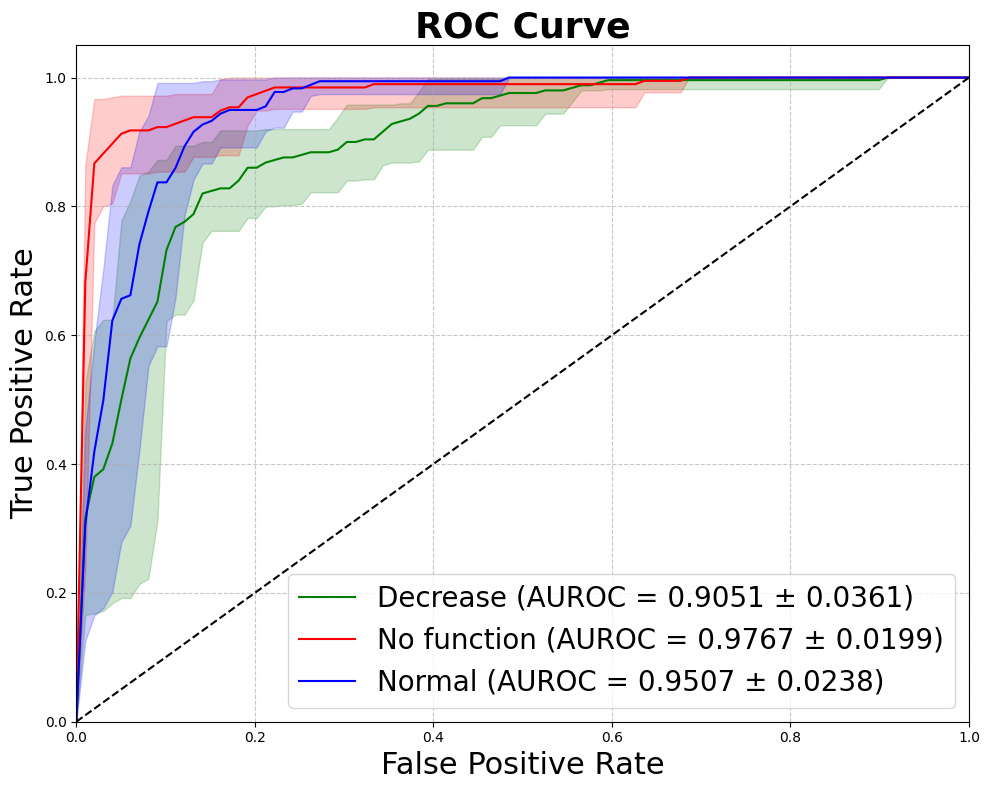

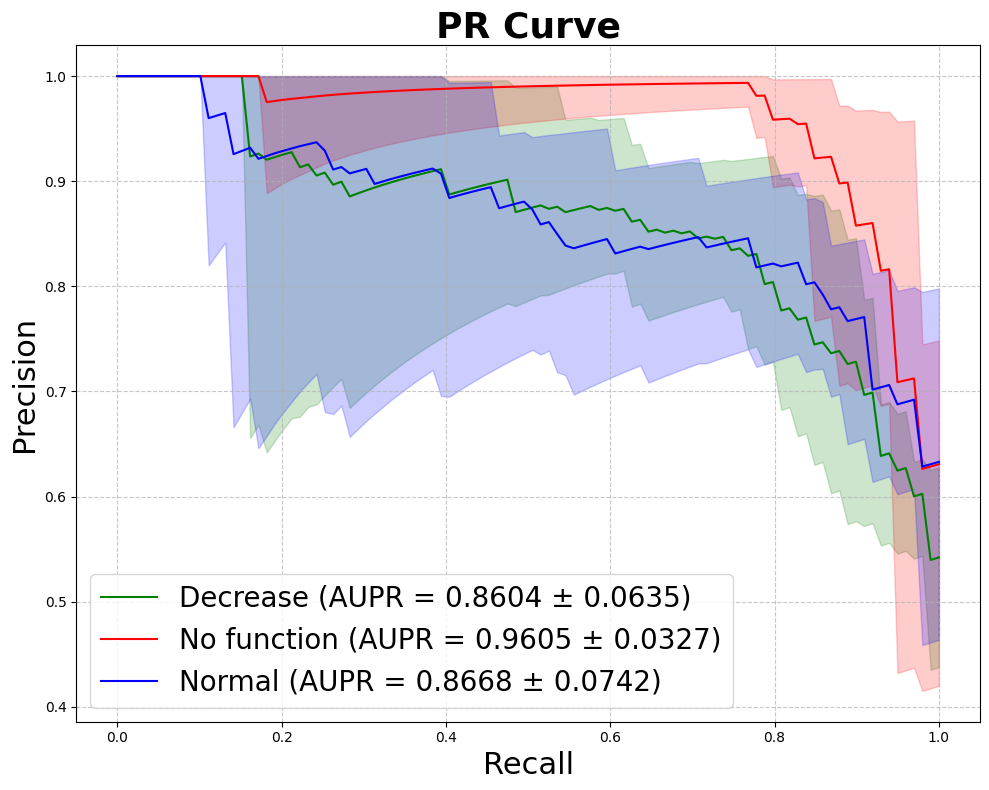

In [25]:
from scipy import stats
def plot_mean_roc_curve(y_true_list, y_probs_list, num_classes=3, font_size=22):
    plt.figure(figsize=(10, 8))
    mean_fpr = np.linspace(0, 1, 100)
    class_labels = ['Decrease', 'No function', 'Normal']
    colors = ['green', 'red', 'blue']
    
    for i in range(num_classes):
        tprs = []
        aucs = []
        for y_true, y_probs in zip(y_true_list, y_probs_list):
            fpr, tpr, _ = roc_curve(y_true == i, y_probs[:, i])
            tprs.append(np.interp(mean_fpr, fpr, tpr))
            tprs[-1][0] = 0.0
            aucs.append(auc(fpr, tpr))
        
        mean_tpr = np.mean(tprs, axis=0)
        mean_tpr[-1] = 1.0
        mean_auc = np.mean(aucs)
        std_auc = np.std(aucs)
        
        # Calculate 95% confidence interval
        tprs_upper = np.percentile(tprs, 97.5, axis=0)
        tprs_lower = np.percentile(tprs, 2.5, axis=0)
        
        plt.plot(mean_fpr, mean_tpr, color=colors[i], 
                 label=f'{class_labels[i]} (AUROC = {mean_auc:.4f} ± {std_auc:.4f})')
        plt.fill_between(mean_fpr, tprs_lower, tprs_upper, color=colors[i], alpha=0.2)

    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=font_size)
    plt.ylabel('True Positive Rate', fontsize=font_size)
    plt.title('ROC Curve', fontsize=font_size + 4, fontweight='bold')
    plt.legend(loc='lower right', fontsize=font_size - 2)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

def plot_mean_precision_recall_curve(y_true_list, y_probs_list, num_classes=3, font_size=22):
    plt.figure(figsize=(10, 8))
    mean_recall = np.linspace(0, 1, 100)
    class_labels = ['Decrease', 'No function', 'Normal']
    colors = ['green', 'red', 'blue']
    
    for i in range(num_classes):
        precisions = []
        auprs = []
        for y_true, y_probs in zip(y_true_list, y_probs_list):
            precision, recall, _ = precision_recall_curve(y_true == i, y_probs[:, i])
            precisions.append(np.interp(mean_recall, recall[::-1], precision[::-1]))
            auprs.append(np.trapz(precision, recall))
        
        mean_precision = np.mean(precisions, axis=0)
        mean_aupr = np.mean(auprs)
        std_aupr = np.std(auprs)
        
        # Calculate 95% confidence interval
        precisions_upper = np.percentile(precisions, 97.5, axis=0)
        precisions_lower = np.percentile(precisions, 2.5, axis=0)
        
        plt.plot(mean_recall, mean_precision, color=colors[i],
                 label=f'{class_labels[i]} (AUPR = {abs(mean_aupr):.4f} ± {abs(std_aupr):.4f})')
        plt.fill_between(mean_recall, precisions_lower, precisions_upper, color=colors[i], alpha=0.2)

    plt.xlabel('Recall', fontsize=font_size)
    plt.ylabel('Precision', fontsize=font_size)
    plt.title('PR Curve', fontsize=font_size + 4, fontweight='bold')
    plt.legend(loc='lower left', fontsize=font_size - 2)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

# ROC 및 PR 커브 시각화
plot_mean_roc_curve(all_test_labels_list, all_test_preds_list, num_classes=3)
plot_mean_precision_recall_curve(all_test_labels_list, all_test_preds_list, num_classes=3)